# Dense vs Convolutional Neural Networks


In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from torch import nn, optim
from torchvision import transforms

torch.random.manual_seed(0)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)


cpu


Link to the data:
https://drive.google.com/drive/folders/1VjQNIKuGGU7G-CZMsmFIn__M_v7nywEZ?usp=sharing

_(this is a subset of "skin-cancer-mnist-ham10000")_


Read the CSV file and display the first few rows of the data.

In [2]:
df = pd.read_csv('../data/HAM2000/HAM2000.csv')
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0006518,ISIC_0027618,nv,follow_up,35.0,male,back
1,HAM_0004666,ISIC_0029165,nv,follow_up,55.0,male,upper extremity
2,HAM_0006455,ISIC_0029690,nv,follow_up,50.0,male,lower extremity
3,HAM_0003653,ISIC_0030139,nv,histo,45.0,male,back
4,HAM_0001330,ISIC_0026818,nv,histo,20.0,female,abdomen


Create a dataset with a transformation to resize the images to 64x64 pixels.

Add data augmentation (random horizontal/vertical flip) to the dataset.

torch.Size([3, 64, 64])
torch.Size([64, 64, 3])


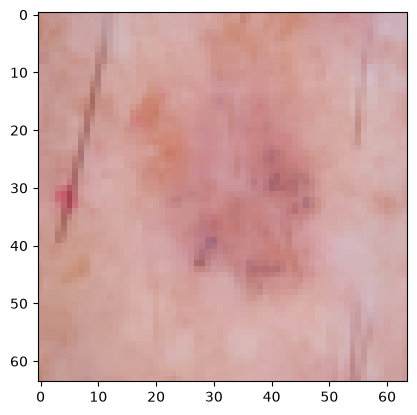

In [3]:
transfo = transforms.Compose(
    [
        transforms.Resize( (64,64) ),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor()
    ]
)

dataset = torchvision.datasets.ImageFolder(root='../data/HAM2000/', transform=transfo)
dataset.find_classes('../data/HAM2000')

print(dataset[0][0].shape)
print(dataset[0][0].permute(1,2,0).shape)
plt.imshow(dataset[0][0].permute(1,2,0))

Split the dataset into training and test sets.

Create dataloaders for the training and test sets.

In [4]:
train_size = int(0.8*len(dataset))
test_size = len(dataset) - train_size

train_data, test_data = torch.utils.data.random_split(dataset, [train_size, test_size])
len(dataset), len(train_data), len(test_data)

(2000, 1600, 400)

In [5]:
train_loader = torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=64, shuffle=False)


In [6]:
for x,y in train_loader:
    print(x.shape, y.shape)
    print(y)
    break

torch.Size([64, 3, 64, 64]) torch.Size([64])
tensor([1, 2, 3, 2, 3, 0, 0, 2, 0, 1, 1, 3, 0, 2, 2, 1, 0, 1, 0, 1, 0, 2, 1, 3,
        2, 2, 1, 3, 2, 0, 3, 1, 3, 2, 1, 0, 2, 1, 1, 0, 2, 0, 2, 3, 2, 2, 0, 0,
        3, 3, 3, 1, 1, 0, 3, 0, 0, 3, 3, 2, 1, 0, 1, 1])


### Linear Model

Create a linear model with two hidden layer.

In [7]:
class SkinLinearNet(nn.Module):
    def __init__(self, hidden_size1, hidden_size2):
        super().__init__()
        self.fc1 = nn.Linear(64*64*3, hidden_size1)
        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.fc3 = nn.Linear(hidden_size2, 4)

    def forward(self, x):
        x = x.view(-1, 64*64*3)
        x = self.fc1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.ReLU()(x)
        x = self.fc3(x)
        x = nn.Softmax(dim=1)(x)
        return x

net = SkinLinearNet(512, 32)
fake_x = torch.randn((8, 3, 64, 64))

out = net(fake_x)
out, torch.argmax(out, dim=1)


(tensor([[0.2227, 0.2459, 0.2651, 0.2662],
         [0.2641, 0.2537, 0.2360, 0.2462],
         [0.2549, 0.2319, 0.2475, 0.2657],
         [0.2204, 0.2305, 0.2860, 0.2632],
         [0.2183, 0.2391, 0.2816, 0.2610],
         [0.2197, 0.2636, 0.2696, 0.2471],
         [0.2365, 0.2168, 0.2601, 0.2866],
         [0.2301, 0.2424, 0.2787, 0.2488]], grad_fn=<SoftmaxBackward0>),
 tensor([3, 0, 3, 2, 2, 2, 3, 2]))

Create a loss function and an optimizer.

In [8]:
opt = optim.Adam(net.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

Write the training loop.

In [9]:
net = SkinLinearNet(512, 32)
opt = optim.Adam(net.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

n_epochs = 10
losses = []
accuracies = []

net.train()
for epoch in range(1, n_epochs+1):
    running_correct = 0
    for image_batch, label_batch in train_loader:
        probas = net(image_batch)
        predictions = torch.argmax(probas, dim=1)
        correct = (predictions == label_batch).sum()
        running_correct += correct.item()
        loss = loss_fn(probas, label_batch)
        loss.backward()
        losses.append(loss.item())
        opt.step()
        opt.zero_grad()
    accuracies.append(running_correct/len(train_data))
    print(f'Epoch {epoch}/{n_epochs}: {running_correct} / {len(train_data)}')

Epoch 1/10: 460 / 1600
Epoch 2/10: 563 / 1600
Epoch 3/10: 611 / 1600
Epoch 4/10: 644 / 1600
Epoch 5/10: 660 / 1600
Epoch 6/10: 688 / 1600
Epoch 7/10: 712 / 1600
Epoch 8/10: 771 / 1600
Epoch 9/10: 776 / 1600
Epoch 10/10: 754 / 1600


Plot the loss and accuracy through epochs.

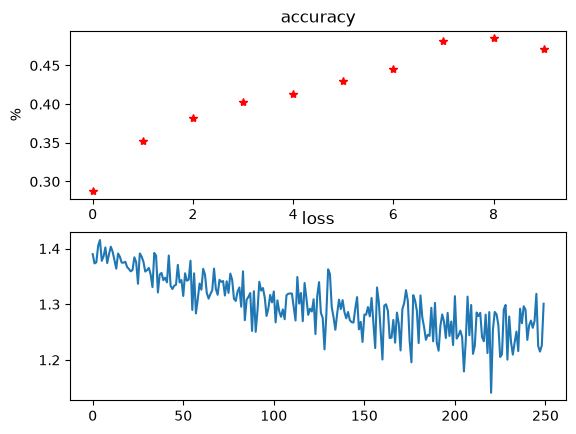

In [10]:
plt.subplot(2, 1, 1)
plt.plot(accuracies, '*r')
plt.title('accuracy')
plt.ylabel('%')
plt.subplot(2, 1, 2)
plt.plot(losses)
plt.title('loss')
plt.show()

Test the model on a few images of the test set.

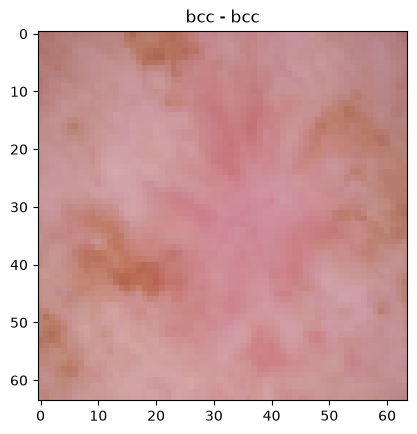

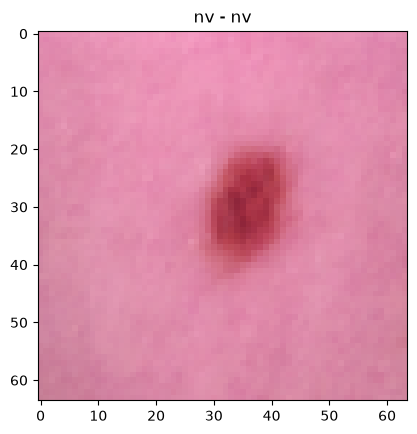

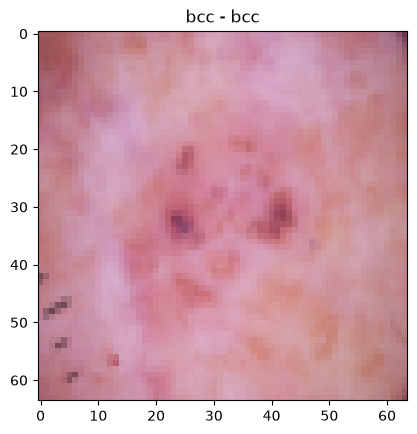

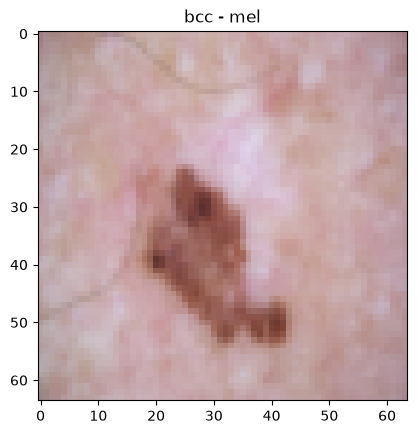

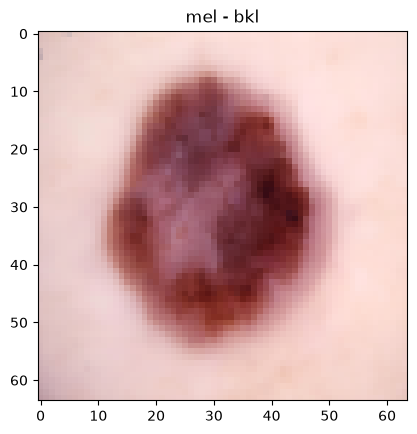

In [11]:
for i in range(5):
    image, label = test_data[i]
    probas = net(image)
    pred = torch.argmax(probas)
    plt.imshow(image.permute(1,2,0))
    plt.title(f'{dataset.classes[pred]} - {dataset.classes[label]}')
    plt.show()


Compute the accuracy of the model on the test set.

In [12]:
net.eval()
correct = 0
for image_batch, label_batch in test_loader:
    probas = net(image_batch)
    pred = torch.argmax(probas, dim=1)
    correct += (pred == label_batch).sum()
acc = correct / len(test_data)
print(f'Test accuracy: {acc*100} %')

Test accuracy: 47.5 %


### Conv Model

Create a convolutional model with a few convolutional layers and two linear layers (for the classification).

In [13]:
class SkinConvNet(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()
        # self.conv1 = nn.Conv2d(3, 8, kernel_size=(5,5), stride=(2,2))
        self.conv1 = nn.Conv2d(3, 8, kernel_size=5, stride=2)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=5)
        self.conv4 = nn.Conv2d(32, 32, kernel_size=5)
        self.fc1 = nn.Linear(32*18*18, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 4)

    def forward(self, x):
        x = self.conv1(x)
        x = nn.ReLU()(x)
        x = self.conv2(x)
        x = nn.ReLU()(x)
        x = self.conv3(x)
        x = nn.ReLU()(x)
        x = self.conv4(x)
        x = nn.ReLU()(x)
        x = x.view(-1, 32*18*18)
        x = self.fc1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.Softmax(dim=1)(x)
        return x

net = SkinConvNet()
fake_x = torch.randn((4, 3, 64, 64))
out = net(fake_x)
out.shape

torch.Size([4, 4])

Create a loss function and an optimizer, and train loop.

In [14]:
net = SkinConvNet()
opt = optim.Adam(net.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

n_epochs = 10
losses = []
accuracies = []

net.train()
for epoch in range(1, n_epochs+1):
    running_correct = 0
    for image_batch, label_batch in train_loader:
        probas = net(image_batch)
        predictions = torch.argmax(probas, dim=1)
        correct = (predictions == label_batch).sum()
        running_correct += correct.item()
        loss = loss_fn(probas, label_batch)
        loss.backward()
        losses.append(loss.item())
        opt.step()
        opt.zero_grad()
    accuracies.append(running_correct/len(train_data))
    print(f'Epoch {epoch}/{n_epochs}: {running_correct} / {len(train_data)}')

Epoch 1/10: 551 / 1600
Epoch 2/10: 602 / 1600
Epoch 3/10: 666 / 1600
Epoch 4/10: 679 / 1600
Epoch 5/10: 683 / 1600
Epoch 6/10: 700 / 1600
Epoch 7/10: 712 / 1600
Epoch 8/10: 717 / 1600
Epoch 9/10: 731 / 1600
Epoch 10/10: 751 / 1600


Plot the loss and accuracy through epochs.

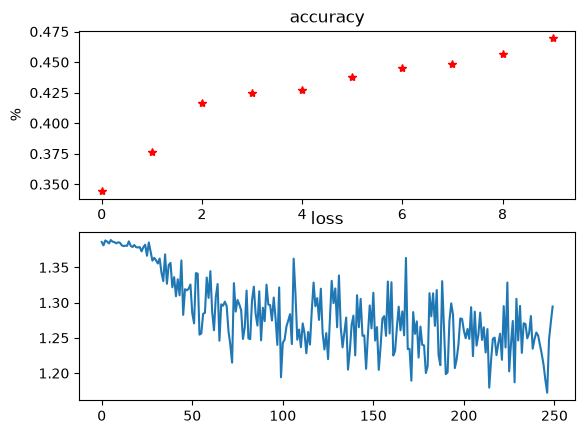

In [15]:
plt.subplot(2, 1, 1)
plt.plot(accuracies, '*r')
plt.title('accuracy')
plt.ylabel('%')
plt.subplot(2, 1, 2)
plt.plot(losses)
plt.title('loss')
plt.show()

Test the model on a few images of the test set.

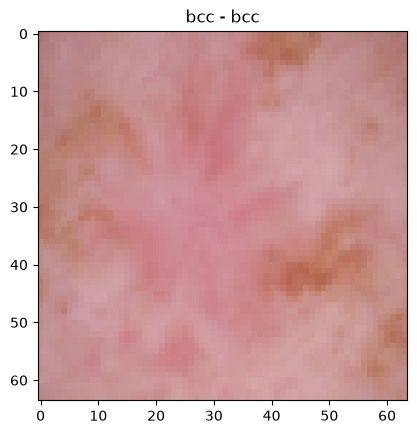

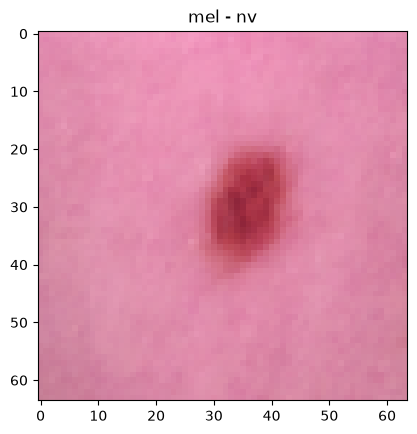

In [16]:
for i in range(2):
    image, label = test_data[i]
    probas = net(image)
    pred = torch.argmax(probas)
    plt.imshow(image.permute(1,2,0))
    plt.title(f'{dataset.classes[pred]} - {dataset.classes[label]}')
    plt.show()

Compute the accuracy of the model on the test set.

In [17]:
net.eval()
correct = 0
for image_batch, label_batch in test_loader:
    probas = net(image_batch)
    pred = torch.argmax(probas, dim=1)
    correct += (pred == label_batch).sum()
acc = correct / len(test_data)
print(f'Test accuracy: {acc*100} %')

Test accuracy: 49.75 %


Compare the training time and accuracy of the two models.

----

Add Batch Norm after each layer:
conv/fc => bn => relu

In [18]:
class SkinConvNormNet(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, kernel_size=5, stride=2)
        self.bn1 = nn.BatchNorm2d(8)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5)
        self.bn2 = nn.BatchNorm2d(16)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=5)
        self.bn3 = nn.BatchNorm2d(32)
        self.conv4 = nn.Conv2d(32, 32, kernel_size=5)
        self.bn4 = nn.BatchNorm2d(32)
        self.fc1 = nn.Linear(32*18*18, hidden_size)
        self.fc_bn1 = nn.BatchNorm1d(hidden_size)
        self.fc2 = nn.Linear(hidden_size, 4)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = nn.ReLU()(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = nn.ReLU()(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = nn.ReLU()(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = nn.ReLU()(x)
        x = x.view(-1, 32*18*18)
        x = self.fc1(x)
        x = self.fc_bn1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.Softmax(dim=1)(x)
        return x

net = SkinConvNormNet()
fake_x = torch.randn((2, 3, 64, 64))
out = net(fake_x)
out

tensor([[0.2989, 0.2142, 0.3088, 0.1780],
        [0.2528, 0.0933, 0.4253, 0.2286]], grad_fn=<SoftmaxBackward0>)

In [35]:
net = SkinConvNormNet()
opt = optim.Adam(net.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

n_epochs = 20
losses = []
accuracies = []

net.train()
for epoch in range(1, n_epochs+1):
    running_correct = 0
    for image_batch, label_batch in train_loader:
        probas = net(image_batch)
        predictions = torch.argmax(probas, dim=1)
        correct = (predictions == label_batch).sum()
        running_correct += correct.item()
        loss = loss_fn(probas, label_batch)
        loss.backward()
        losses.append(loss.item())
        opt.step()
        opt.zero_grad()
    accuracies.append(running_correct/len(train_data))
    print(f'Epoch {epoch}/{n_epochs}: {running_correct} / {len(train_data)}')

Epoch 1/20: 782 / 1600
Epoch 2/20: 938 / 1600
Epoch 3/20: 984 / 1600
Epoch 4/20: 1029 / 1600
Epoch 5/20: 1071 / 1600
Epoch 6/20: 1103 / 1600
Epoch 7/20: 1143 / 1600
Epoch 8/20: 1161 / 1600
Epoch 9/20: 1194 / 1600
Epoch 10/20: 1236 / 1600
Epoch 11/20: 1290 / 1600
Epoch 12/20: 1305 / 1600
Epoch 13/20: 1315 / 1600
Epoch 14/20: 1342 / 1600
Epoch 15/20: 1367 / 1600
Epoch 16/20: 1391 / 1600
Epoch 17/20: 1431 / 1600
Epoch 18/20: 1436 / 1600
Epoch 19/20: 1435 / 1600
Epoch 20/20: 1444 / 1600


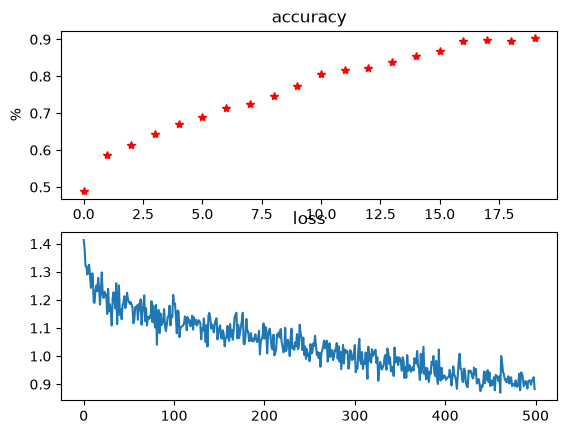

In [36]:
plt.subplot(2, 1, 1)
plt.plot(accuracies, '*r')
plt.title('accuracy')
plt.ylabel('%')
plt.subplot(2, 1, 2)
plt.plot(losses)
plt.title('loss')
plt.show()

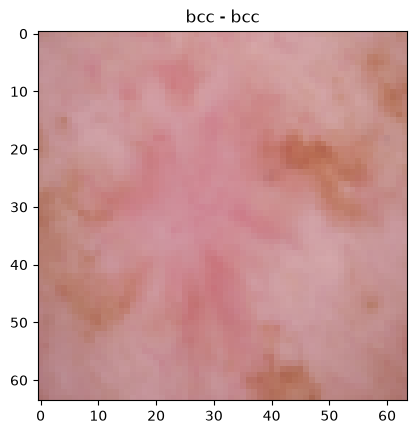

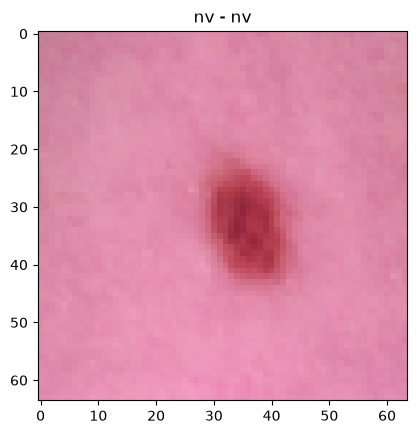

In [37]:
net.eval()
for i in range(2):
    image, label = test_data[i]
    probas = net(image[None,:,:,:])
    pred = torch.argmax(probas)
    plt.imshow(image.permute(1,2,0))
    plt.title(f'{dataset.classes[pred]} - {dataset.classes[label]}')
    plt.show()

In [38]:
net.eval()
correct = 0
for image_batch, label_batch in test_loader:
    probas = net(image_batch)
    pred = torch.argmax(probas, dim=1)
    correct += (pred == label_batch).sum()
acc = correct / len(test_data)
print(f'Test accuracy: {acc*100} %')

Test accuracy: 64.75 %


-----

BONUS: Create a custom dataset and return the image, the class, and some tabular data from the CSV file.

You may use the 'bis' version of the dataset for this task:
https://drive.google.com/drive/folders/1VjQNIKuGGU7G-CZMsmFIn__M_v7nywEZ?usp=sharing

2000 images, 19 tabular features: ['age', 'sex_female', 'sex_male', 'sex_unknown', 'localization_abdomen', 'localization_acral', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_foot', 'localization_genital', 'localization_hand', 'localization_lower extremity', 'localization_neck', 'localization_scalp', 'localization_trunk', 'localization_unknown', 'localization_upper extremity']


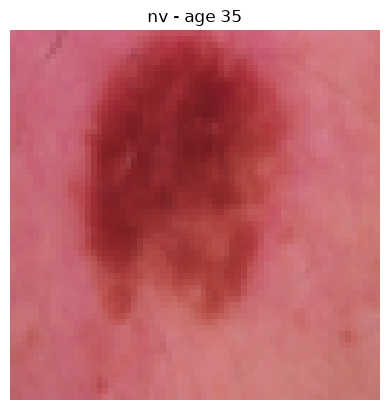

In [23]:
from PIL import Image


class SkinDataset(torch.utils.data.Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform
        df = pd.read_csv(os.path.join(root, "metadata.csv"))
        # find the image of each row, whatever the folder structure
        paths = {}
        for dirpath, _, filenames in os.walk(root):
            for filename in filenames:
                name, ext = os.path.splitext(filename)
                if ext.lower() in (".jpg", ".jpeg", ".png"):
                    paths[name] = os.path.join(dirpath, filename)
        df = df[df["image_id"].isin(paths)].reset_index(drop=True)
        self.paths = [paths[image_id] for image_id in df["image_id"]]
        self.classes = sorted(df["dx"].unique())
        self.labels = torch.tensor(df["dx"].map(self.classes.index).values)
        # tabular data: age (normalized) + one-hot encoded sex & localization
        # (we do NOT use dx_type: it is how the diagnosis was made, so it leaks the label)
        age = df["age"].fillna(df["age"].mean()) / 100
        one_hot = pd.get_dummies(df[["sex", "localization"]], dtype=float)
        self.tabular_names = ["age"] + list(one_hot.columns)
        self.tabular = torch.tensor(
            pd.concat([age, one_hot], axis=1).values, dtype=torch.float32
        )

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.tabular[idx], self.labels[idx]


tab_dataset = SkinDataset("../data/HAM/", transform=transfo)
n_tabular = tab_dataset.tabular.shape[1]
print(len(tab_dataset), "images,", n_tabular, "tabular features:", tab_dataset.tabular_names)

tab_train_size = int(0.8 * len(tab_dataset))
tab_test_size = len(tab_dataset) - tab_train_size
tab_train_dataset, tab_test_dataset = torch.utils.data.random_split(
    tab_dataset, [tab_train_size, tab_test_size]
)
tab_train_loader = torch.utils.data.DataLoader(tab_train_dataset, batch_size=64, shuffle=True)
tab_test_loader = torch.utils.data.DataLoader(tab_test_dataset, batch_size=64)

image, tabular, label = tab_dataset[0]
plt.imshow(image.permute(1, 2, 0))
plt.title(f"{tab_dataset.classes[label]} - age {100*tabular[0]:.0f}")
plt.axis("off")
plt.show()

In [24]:
tab_dataset[0][0].shape

torch.Size([3, 64, 64])

In [25]:
tab_dataset.tabular_names

['age',
 'sex_female',
 'sex_male',
 'sex_unknown',
 'localization_abdomen',
 'localization_acral',
 'localization_back',
 'localization_chest',
 'localization_ear',
 'localization_face',
 'localization_foot',
 'localization_genital',
 'localization_hand',
 'localization_lower extremity',
 'localization_neck',
 'localization_scalp',
 'localization_trunk',
 'localization_unknown',
 'localization_upper extremity']

In [26]:
tab_dataset[1][1], tab_dataset[1][1].shape

(tensor([0.5500, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         1.0000]),
 torch.Size([19]))

In [27]:
tab_dataset.classes

['bcc', 'bkl', 'mel', 'nv']

In [28]:
tab_dataset[1][2]

tensor(3)

Create a model that uses the tabular data and the image to predict the class.

In [29]:
class SkinConvNormTabNet(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, kernel_size=5, stride=2)
        self.bn1 = nn.BatchNorm2d(8)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5)
        self.bn2 = nn.BatchNorm2d(16)
        self.conv3 = nn.Conv2d(16, 32, kernel_size=5)
        self.bn3 = nn.BatchNorm2d(32)
        self.conv4 = nn.Conv2d(32, 32, kernel_size=5)
        self.bn4 = nn.BatchNorm2d(32)
        self.fc1 = nn.Linear(32*18*18+19, hidden_size)
        self.fc_bn1 = nn.BatchNorm1d(hidden_size)
        self.fc2 = nn.Linear(hidden_size, 4)

    def forward(self, x, y):
        x = self.conv1(x)
        x = self.bn1(x)
        x = nn.ReLU()(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = nn.ReLU()(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = nn.ReLU()(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = nn.ReLU()(x)
        x = x.view(-1, 32*18*18)
        # print(x.shape, y.shape)
        x = torch.cat([x, y], dim=1)
        x = self.fc1(x)
        x = self.fc_bn1(x)
        x = nn.ReLU()(x)
        x = self.fc2(x)
        x = nn.Softmax(dim=1)(x)
        return x

net = SkinConvNormTabNet()
fake_x = torch.randn((2, 3, 64, 64))
fake_y = torch.randn((2, 19))
out = net(fake_x, fake_y)
out

tensor([[0.2036, 0.2896, 0.3091, 0.1977],
        [0.2876, 0.2481, 0.2103, 0.2539]], grad_fn=<SoftmaxBackward0>)

In [30]:
x = torch.randn((2, 5))
y = torch.randn((2, 3))
print('x',  x)
print('y',  y)
torch.cat([x, y], dim=1)


x tensor([[-0.6815, -1.3969, -0.0817,  1.6523, -0.9534],
        [ 1.0520,  0.6414,  1.8981, -1.4558,  1.1294]])
y tensor([[-0.6448,  1.8698,  1.0588],
        [-0.1186,  0.1579,  0.8595]])


tensor([[-0.6815, -1.3969, -0.0817,  1.6523, -0.9534, -0.6448,  1.8698,  1.0588],
        [ 1.0520,  0.6414,  1.8981, -1.4558,  1.1294, -0.1186,  0.1579,  0.8595]])

Create a loss function and an optimizer.

In [31]:
net = SkinConvNormTabNet()
opt = optim.Adam(net.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()

n_epochs = 20
losses = []
accuracies = []

Write the training loop.

In [32]:
net.train()
for epoch in range(1, n_epochs+1):
    running_correct = 0
    for image_batch, tab_batch, label_batch in tab_train_loader:
        probas = net(image_batch, tab_batch)
        predictions = torch.argmax(probas, dim=1)
        correct = (predictions == label_batch).sum()
        running_correct += correct.item()
        loss = loss_fn(probas, label_batch)
        loss.backward()
        losses.append(loss.item())
        opt.step()
        opt.zero_grad()
    accuracies.append(running_correct/len(train_data))
    print(f'Epoch {epoch}/{n_epochs}: {running_correct} / {len(train_data)}')

Epoch 1/20: 831 / 1600
Epoch 2/20: 967 / 1600
Epoch 3/20: 995 / 1600
Epoch 4/20: 1048 / 1600
Epoch 5/20: 1066 / 1600
Epoch 6/20: 1096 / 1600
Epoch 7/20: 1118 / 1600
Epoch 8/20: 1150 / 1600
Epoch 9/20: 1175 / 1600
Epoch 10/20: 1212 / 1600
Epoch 11/20: 1226 / 1600
Epoch 12/20: 1268 / 1600
Epoch 13/20: 1290 / 1600
Epoch 14/20: 1313 / 1600
Epoch 15/20: 1337 / 1600
Epoch 16/20: 1367 / 1600
Epoch 17/20: 1371 / 1600
Epoch 18/20: 1399 / 1600
Epoch 19/20: 1426 / 1600
Epoch 20/20: 1424 / 1600


Plot the loss and accuracy through epochs.

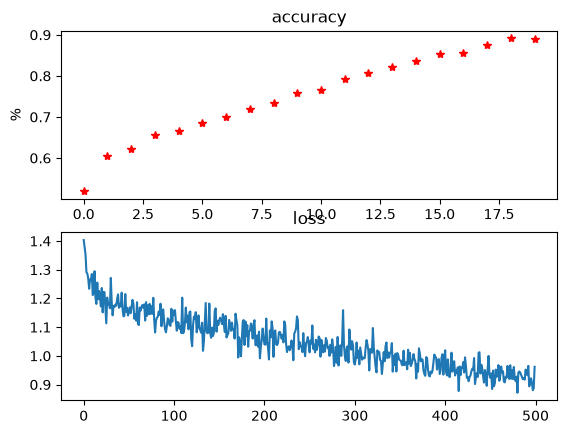

In [33]:
plt.subplot(2, 1, 1)
plt.plot(accuracies, '*r')
plt.title('accuracy')
plt.ylabel('%')
plt.subplot(2, 1, 2)
plt.plot(losses)
plt.title('loss')
plt.show()

Compute the accuracy of the model on the test set.

In [34]:
net.eval()
correct = 0
for image_batch, tab_batch, label_batch in tab_test_loader:
    probas = net(image_batch, tab_batch)
    pred = torch.argmax(probas, dim=1)
    correct += (pred == label_batch).sum()
acc = correct / len(test_data)
print(f'Test accuracy: {acc*100} %')

Test accuracy: 66.0 %
